# 02 — First-Order Optimizer Comparison

## Purpose

This notebook provides a controlled, illustrative comparison of four first-order optimization methods on one synthetic logistic-regression problem: Batch Gradient Descent, Stochastic Gradient Descent (SGD), Momentum, and Adam.

The primary, repeated empirical comparison is performed on real datasets in Notebook 04. This notebook is a compact demonstration of the optimizer mechanics and convergence traces, not a final statistical benchmark.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_project_root(start=None):
    """Find the repository root from the current Jupyter working directory."""
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src" / "logistic_regression.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Open Jupyter from the repository "
        "folder or one of its subfolders."
    )


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import logistic_regression, optimizers

FIGURES_PATH = PROJECT_ROOT / "results" / "figures"
TABLES_PATH = PROJECT_ROOT / "results" / "tables"
FIGURES_PATH.mkdir(parents=True, exist_ok=True)
TABLES_PATH.mkdir(parents=True, exist_ok=True)

## 1. Generate a reproducible synthetic dataset

All optimizers use the same observations and labels. Parameters are initialized to zero by the shared model implementation. The training shuffle is reproduced for each optimizer through a fixed `random_state`.

In [2]:
SEED = 42
rng = np.random.default_rng(SEED)
X = rng.normal(size=(500, 3))
true_intercept = 0.25
true_weights = np.array([1.5, -2.0, 0.8])
probabilities = logistic_regression.sigmoid(true_intercept + X @ true_weights)
y = (rng.random(X.shape[0]) < probabilities).astype(int)

print("Observations:", X.shape[0])
print("Features:", X.shape[1])
print("Class counts:", dict(zip(*np.unique(y, return_counts=True))))

Observations: 500
Features: 3
Class counts: {np.int64(0): np.int64(235), np.int64(1): np.int64(265)}


## 2. Configure the optimizers

Batch GD, Momentum, and Adam use full-batch gradients. SGD uses one observation per update. Therefore, the number of parameter updates per epoch differs: this notebook compares the characteristic training behaviour by epoch, not equal computational budgets.

In [3]:
EPOCHS = 100
L2 = 0.01

experiment_config = {
    "Batch GD": {
        "optimizer": optimizers.GradientDescent(learning_rate=0.1),
        "batch_size": len(y),
    },
    "SGD": {
        "optimizer": optimizers.GradientDescent(learning_rate=0.01),
        "batch_size": 1,
    },
    "Momentum": {
        "optimizer": optimizers.Momentum(learning_rate=0.1, beta=0.9),
        "batch_size": len(y),
    },
    "Adam": {
        "optimizer": optimizers.Adam(learning_rate=0.01),
        "batch_size": len(y),
    },
}

print("Epochs:", EPOCHS)
print("L2 penalty:", L2)

Epochs: 100
L2 penalty: 0.01


## 3. Train and compare

The Momentum implementation uses an exponential moving average of gradients:

$$
 v_t=\beta v_{t-1}+(1-\beta)g_t,\qquad
 \theta_{t+1}=\theta_t-\eta v_t.
$$

Adam maintains bias-corrected first and second moments. The exact implementations are maintained centrally in `src/optimizers.py`.

In [4]:
trained_models = {}
records = []

for optimizer_name, config in experiment_config.items():
    model = logistic_regression.LogisticRegression(l2=L2)
    model.fit(
        X,
        y,
        optimizer=config["optimizer"],
        epochs=EPOCHS,
        batch_size=config["batch_size"],
        shuffle=True,
        random_state=SEED,
    )
    trained_models[optimizer_name] = model

    updates_per_epoch = int(np.ceil(len(y) / config["batch_size"]))
    records.append(
        {
            "Optimizer": optimizer_name,
            "Batch Size": config["batch_size"],
            "Updates per Epoch": updates_per_epoch,
            "Total Updates": updates_per_epoch * EPOCHS,
            "Initial Loss": logistic_regression.binary_cross_entropy(
                logistic_regression.add_intercept(X), y,
                np.zeros(X.shape[1] + 1), l2=L2
            ),
            "Final Training Loss": model.loss_history[-1],
            "Training Accuracy": np.mean(model.predict(X) == y),
        }
    )

optimizer_summary = pd.DataFrame(records).sort_values("Optimizer")
display(optimizer_summary.round(6))

,Optimizer,Batch Size,Updates per Epoch,Total Updates,Initial Loss,Final Training Loss,Training Accuracy
3,Adam,500,1,100,0.693147,0.467005,0.792
0,Batch GD,500,1,100,0.693147,0.448139,0.796
2,Momentum,500,1,100,0.693147,0.445728,0.796
1,SGD,1,500,50000,0.693147,0.425334,0.796


## 4. Convergence traces

The y-axis is logarithmic to make differences in loss reduction easier to inspect. Epochs are displayed on the horizontal axis. Because SGD makes many more updates per epoch than full-batch methods, interpret these curves as an illustrative comparison rather than an equal-compute benchmark.

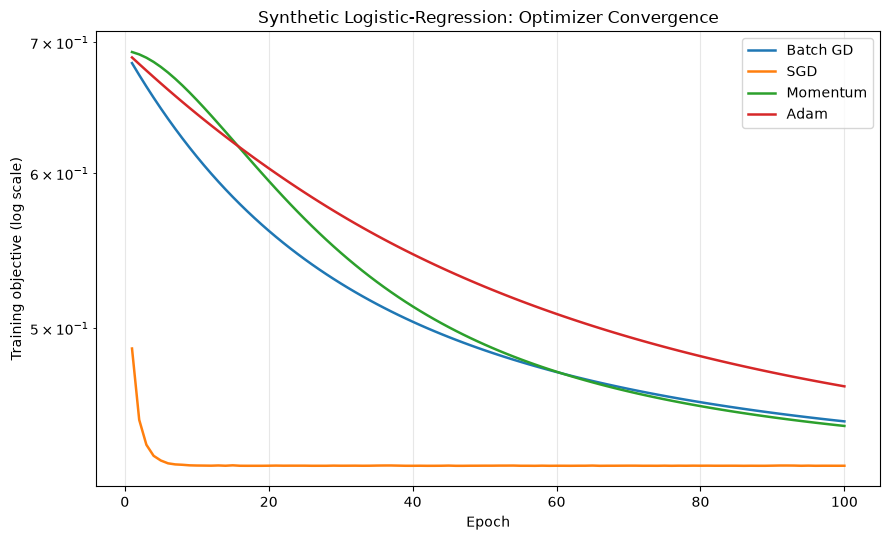

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for optimizer_name, model in trained_models.items():
    ax.plot(
        np.arange(1, len(model.loss_history) + 1),
        model.loss_history,
        label=optimizer_name,
        linewidth=1.8,
    )

ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training objective (log scale)")
ax.set_title("Synthetic Logistic-Regression: Optimizer Convergence")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_PATH / "optimizer_comparison_synthetic.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Interpretation

The summary table and plot is used to describe the observed convergence behaviour. Ranking the optimizers from this single synthetic run alone is avoided: the methods use different batch sizes, the learning rates are illustrative, and no repeated-seed statistical analysis is performed here.